# The managers before Conte, and the players he brought in

1. **Five spells, one club.** Mourinho's 2014/15 champions, Mourinho's 2015/16 collapse, Hiddink's interim spell,
   Conte's first six games with a back four, and Conte's 3-4-3. Per-match numbers from every shot (Understat).
2. **The signings before and after.** Each newcomer's 2015/16 season at his old club against his 2016/17 season at Chelsea, per 90 minutes.
3. **Newcomer vs predecessor.** Each newcomer against the Chelsea player who did that job in 2015/16.

Note on part 2: Alonso (Serie A) and Luiz (Ligue 1) played in different leagues the season before. Understat uses the same
xG model across leagues, but the opposition and the team around them were different, so read those rows as a change of
role, not a like-for-like test.

In [1]:
from pathlib import Path
import html
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())  # repo root
sys.path.insert(0, str(REPO / "src"))
from football_analytics.viz import leaderboard

U = REPO / "data" / "raw" / "understat"
EXT = ROOT / "data" / "external"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
CHE = "Chelsea"
BLUE, GREY, DARK, MUTED, GOLD = "#1F5FAD", "#B4B2A9", "#3D3D3A", "#6B6A64", "#FDBE11"
GOLD_TEXT = "#9A7200"  # darker gold for text on white
SRC_U = "Data: Understat (via douglasbc/scraping-understat-dataset)"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "axes.grid": True, "grid.color": "#ECEAE4", "grid.linewidth": 0.8, "axes.axisbelow": True,
})


def titles(fig, title, subtitle, source):
    """Title above the axes (va=bottom) and subtitle just under it (va=top) so they never overlap."""
    fig.suptitle(title, x=0.01, y=1.06, ha="left", va="bottom", fontsize=14, fontweight="bold", color=DARK)
    fig.text(0.01, 1.055, subtitle, ha="left", va="top", fontsize=10, color=MUTED)
    fig.text(0.01, -0.04, source, ha="left", va="top", fontsize=8, color=MUTED)


def load_shots(season):
    d = pd.read_csv(U / f"shots_epl_{season}.csv")
    d["team"] = np.where(d.h_a == "h", d.h_team, d.a_team)
    d["opp"] = np.where(d.h_a == "h", d.a_team, d.h_team)
    d["goal"] = d.result == "Goal"
    d["date"] = pd.to_datetime(d.date)
    d["player"] = d.player.map(html.unescape)
    return d


def load_players(season):
    p = pd.read_csv(U / f"players_epl_{season}.csv")
    p["player_name"] = p.player_name.map(html.unescape)
    p["team"] = p.team_title.str.split(",").str[-1]  # players who moved mid-season: last club
    return p


def matches(shots):
    """One row per team per match: goals, xG for and against, points."""
    g = shots.groupby("match_id").agg(date=("date", "first"), h=("h_team", "first"), a=("a_team", "first"),
                                      hg=("h_goals", "first"), ag=("a_goals", "first"))
    xg = shots.groupby(["match_id", "team"]).xG.sum()
    rows = []
    for mid, r in g.iterrows():
        for team, opp, gf, ga in [(r.h, r.a, r.hg, r.ag), (r.a, r.h, r.ag, r.hg)]:
            rows.append(dict(match_id=mid, date=r.date, team=team, opp=opp, home=team == r.h, gf=gf, ga=ga,
                             xgf=xg.get((mid, team), 0.0), xga=xg.get((mid, opp), 0.0),
                             pts=3 if gf > ga else 1 if gf == ga else 0))
    m = pd.DataFrame(rows).sort_values(["team", "date"])
    m["n"] = m.groupby("team").cumcount() + 1
    return m


def expected_points(shots, sims=10_000, seed=42):
    """Replay every match `sims` times: each shot is a goal with probability = its xG."""
    rng = np.random.default_rng(seed)
    out = {}
    for mid, g in shots.groupby("match_id"):
        h, a = g.h_team.iloc[0], g.a_team.iloc[0]
        hx, ax = g[g.team == h].xG.values, g[g.team == a].xG.values
        sh = (rng.random((sims, len(hx))) < hx).sum(1)
        sa = (rng.random((sims, len(ax))) < ax).sum(1)
        out[(mid, h)] = (3 * (sh > sa) + (sh == sa)).mean()
        out[(mid, a)] = (3 * (sa > sh) + (sa == sh)).mean()
    return pd.Series(out, name="xpts")

In [2]:
def spell_rows(season, spells):
    s = load_shots(season)
    m = matches(s)
    m = m[m.team == CHE].copy()
    c = s[s.team == CHE]
    np_c = c[c.situation != "Penalty"]
    m["npg"] = m.match_id.map(np_c[np_c.goal].groupby("match_id").size()).fillna(0)
    m["npxg"] = m.match_id.map(np_c.groupby("match_id").xG.sum()).fillna(0)
    m["sf"] = m.match_id.map(c.groupby("match_id").size()).fillna(0)
    opp = s[(s.team != CHE) & ((s.h_team == CHE) | (s.a_team == CHE))]
    m["sa"] = m.match_id.map(opp.groupby("match_id").size()).fillna(0)
    out = []
    for name, lo, hi in spells:
        d = m[(m.n >= lo) & (m.n <= hi)]
        out.append(dict(spell=name, games=len(d), ppg=d.pts.mean(), gf=d.gf.mean(), ga=d.ga.mean(),
                        xgf=d.xgf.mean(), xga=d.xga.mean(), sf=d.sf.mean(), sa=d.sa.mean(),
                        fin=(d.npg - d.npxg).sum(), fin_pm=(d.npg - d.npxg).mean()))
    return out

rows = (spell_rows("14-15", [("Mourinho 2014/15\n(champions)", 1, 38)])
        + spell_rows("15-16", [("Mourinho 2015/16\n(games 1-16)", 1, 16), ("Hiddink 2015/16\n(games 17-38)", 17, 38)])
        + spell_rows("16-17", [("Conte, back four\n(games 1-6)", 1, 6), ("Conte, 3-4-3\n(games 7-38)", 7, 38)]))
SP = pd.DataFrame(rows)
SP.round(2)

,spell,games,ppg,gf,ga,xgf,xga,sf,sa,fin,fin_pm
0,Mourinho 2014/15\n(champions),38,2.29,1.92,0.84,1.87,0.84,14.87,10.97,0.89,0.02
1,Mourinho 2015/16\n(games 1-16),16,0.94,1.12,1.62,1.22,1.19,14.12,12.25,-4.56,-0.29
2,Hiddink 2015/16\n(games 17-38),22,1.59,1.86,1.23,1.60,1.20,13.73,13.23,4.53,0.21
3,"Conte, back four\n(games 1-6)",6,1.67,1.67,1.50,1.64,0.96,16.67,8.67,-0.10,-0.02
4,"Conte, 3-4-3\n(games 7-38)",32,2.59,2.34,0.75,1.64,0.72,15.03,8.53,21.72,0.68


## 1. Five spells, one club

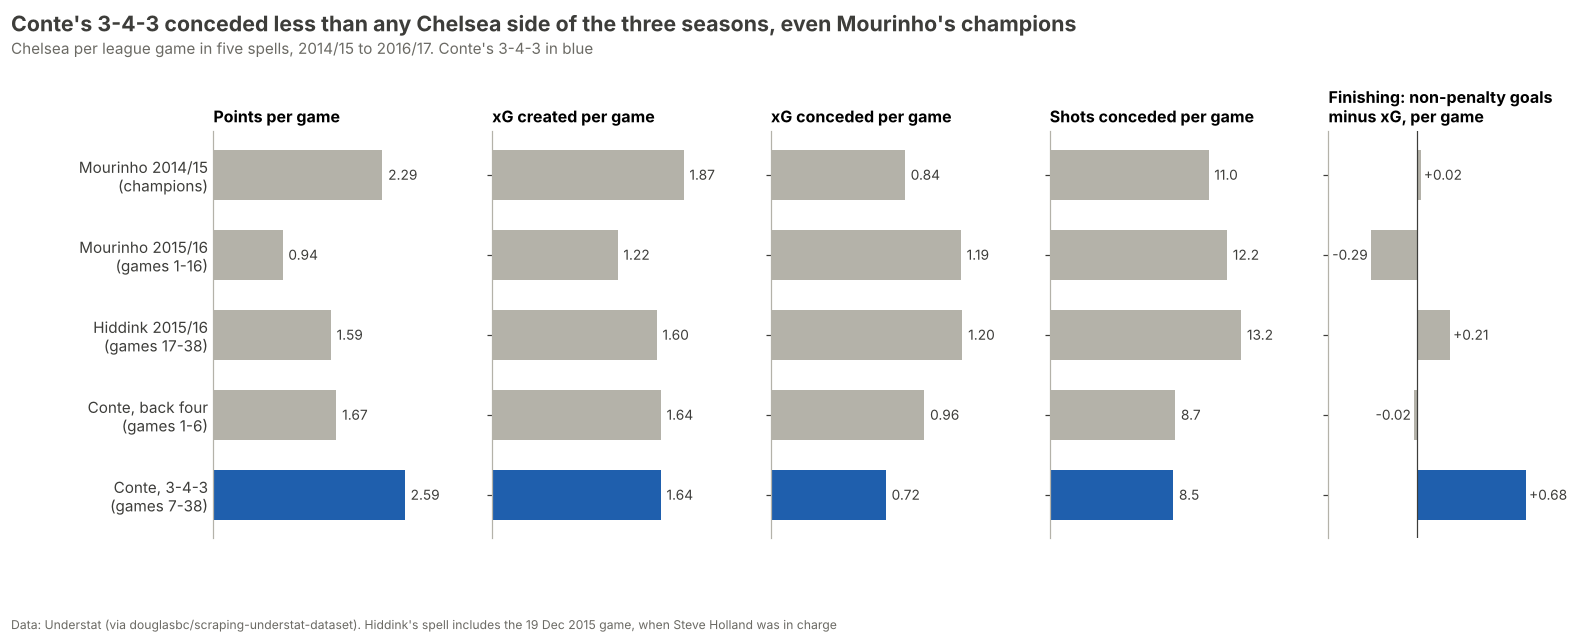

In [3]:
panels = [("ppg", "Points per game", "{:.2f}"), ("xgf", "xG created per game", "{:.2f}"),
          ("xga", "xG conceded per game", "{:.2f}"), ("sa", "Shots conceded per game", "{:.1f}"),
          ("fin_pm", "Finishing: non-penalty goals\nminus xG, per game", "{:+.2f}")]
fig, axes = plt.subplots(1, 5, figsize=(16, 4.8), sharey=True)
y = np.arange(len(SP))[::-1]
cols = [GREY, GREY, GREY, GREY, BLUE]
for ax, (col, lab, fmt) in zip(axes, panels):
    v = SP[col].values
    ax.barh(y, v, color=cols, height=0.62)
    span = max(abs(v).max(), 1e-9)
    for yi, vi in zip(y, v):
        ax.text(vi + (0.03 * span if vi >= 0 else -0.03 * span), yi, fmt.format(vi), va="center",
                ha="left" if vi >= 0 else "right", fontsize=9, color=DARK)
    ax.set_title(lab, fontsize=10.5)
    ax.grid(axis="y", visible=False)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    if col == "fin_pm":
        ax.axvline(0, color=DARK, lw=0.8)
        ax.set_xlim(-0.55, 1.0)
    else:
        ax.set_xlim(0, v.max() * 1.3)
axes[0].set_yticks(y)
axes[0].set_yticklabels(SP.spell)
axes[0].tick_params(axis="y", length=0)
fig.subplots_adjust(wspace=0.12)
titles(fig, "Conte's 3-4-3 conceded less than any Chelsea side of the three seasons, even Mourinho's champions",
       "Chelsea per league game in five spells, 2014/15 to 2016/17. Conte's 3-4-3 in blue",
       SRC_U + ". Hiddink's spell includes the 19 Dec 2015 game, when Steve Holland was in charge")
fig.savefig(FIGS / "17_manager_spells.png")

## 2. The signings, before and after

Per 90 minutes, 2015/16 at the old club vs 2016/17 at Chelsea. Batshuayi is left out of the chart: he played
221 league minutes for Chelsea, too few for per-90 numbers (he scored 5 goals in them).

In [4]:
def load_other(league):
    p = pd.read_csv(U / "other" / f"players_{league}_15-16.csv")
    p["player_name"] = p.player_name.map(html.unescape)
    return p

prev = pd.concat([load_players("15-16"), load_other("serie_a"), load_other("ligue_1")])
now = load_players("16-17")
SIGN = [("N'Golo Kanté", "Leicester (PL)"), ("Marcos Alonso", "Fiorentina (Serie A)"),
        ("David Luiz", "PSG (Ligue 1)"), ("Victor Moses", "West Ham (PL)"), ("Michy Batshuayi", "Marseille (Ligue 1)")]
METRICS = [("xGChain", "xGChain\n(involved in attacks)"), ("xGBuildup", "xGBuildup\n(build-up, no shot or key pass)"),
           ("npxG_xA", "npxG + xA\n(goal threat)"), ("key_passes", "Key passes")]

def per90(r):
    return {"xGChain": r.xGChain / r.time * 90, "xGBuildup": r.xGBuildup / r.time * 90,
            "npxG_xA": (r.npxG + r.xA) / r.time * 90, "key_passes": r.key_passes / r.time * 90}

tab = []
for name, club in SIGN:
    a = prev[prev.player_name == name].iloc[0]; b = now[now.player_name == name].iloc[0]
    tab.append(dict(player=name, old_club=club, old_min=a.time, che_min=b.time,
                    **{f"old_{k}": v for k, v in per90(a).items()}, **{f"che_{k}": v for k, v in per90(b).items()}))
SG = pd.DataFrame(tab)
SG.round(2)

,player,old_club,old_min,che_min,old_xGChain,old_xGBuildup,old_npxG_xA,old_key_passes,che_xGChain,che_xGBuildup,che_npxG_xA,che_key_passes
0,N'Golo Kanté,Leicester (PL),3011,3141,0.33,0.26,0.10,0.90,0.40,0.34,0.12,0.63
1,Marcos Alonso,Fiorentina (Serie A),2343,2696,0.40,0.24,0.29,1.65,0.44,0.27,0.24,0.80
2,David Luiz,PSG (Ligue 1),2086,2959,0.43,0.42,0.14,0.39,0.23,0.21,0.08,0.30
3,Victor Moses,West Ham (PL),982,2519,0.41,0.13,0.31,1.47,0.34,0.18,0.24,1.00
4,Michy Batshuayi,Marseille (Ligue 1),2941,221,0.66,0.13,0.62,0.83,1.87,0.54,1.54,0.41


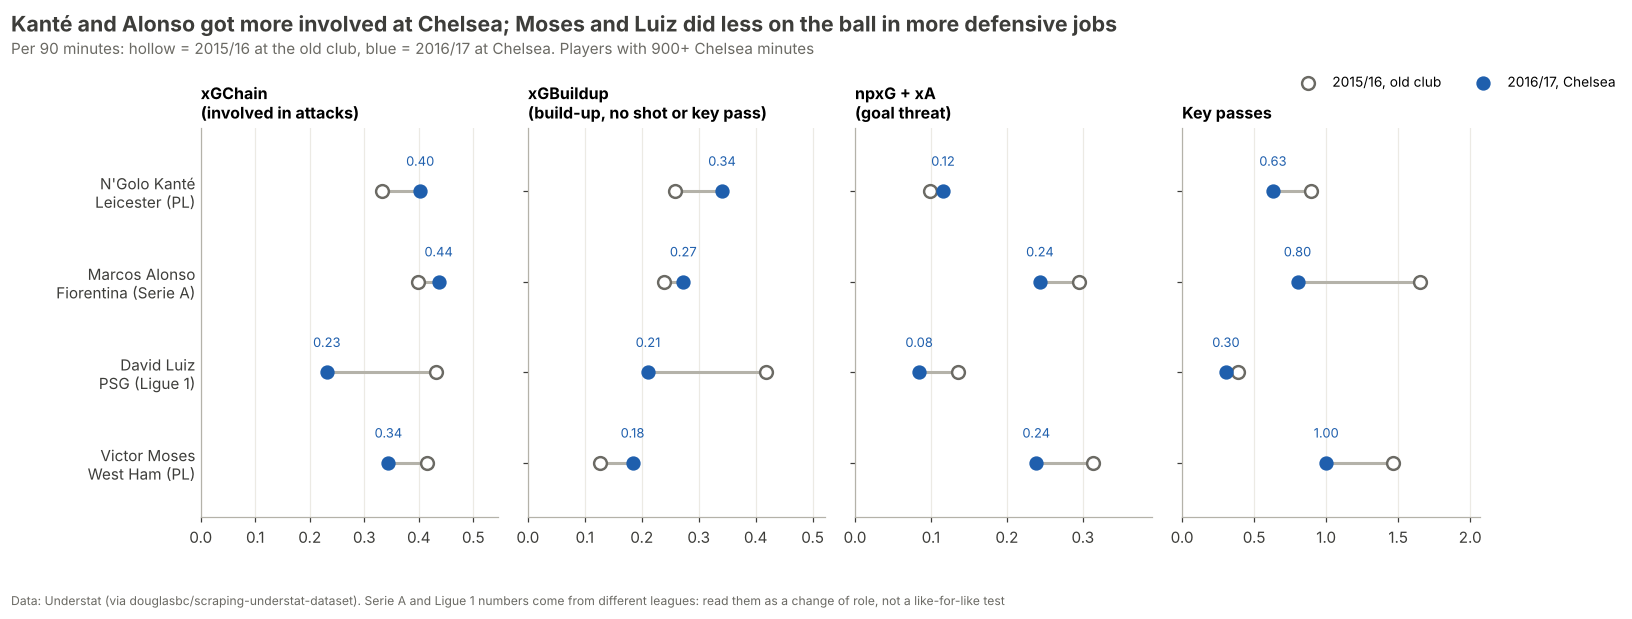

In [5]:
d = SG[SG.che_min >= 900].reset_index(drop=True)
fig, axes = plt.subplots(1, 4, figsize=(15, 4.6), sharey=True)
y = np.arange(len(d))[::-1]
for ax, (k, lab) in zip(axes, METRICS):
    o, c = d[f"old_{k}"].values, d[f"che_{k}"].values
    for yi, oi, ci in zip(y, o, c):
        ax.plot([oi, ci], [yi, yi], color=GREY, lw=2, zorder=1)
    ax.scatter(o, y, s=70, color="white", edgecolor=MUTED, lw=1.6, zorder=2, label="2015/16, old club")
    ax.scatter(c, y, s=70, color=BLUE, zorder=3, label="2016/17, Chelsea")
    for yi, oi, ci in zip(y, o, c):
        ax.text(ci, yi + 0.28, f"{ci:.2f}", ha="center", fontsize=8.5, color=BLUE)
    ax.set_title(lab, fontsize=10.5)
    ax.set_xlim(0, max(o.max(), c.max()) * 1.25)
    ax.grid(axis="y", visible=False)
    ax.set_ylim(-0.6, len(d) - 0.3)
axes[0].set_yticks(y)
axes[0].set_yticklabels([f"{r.player}\n{r.old_club}" for r in d.itertuples()])
axes[0].tick_params(axis="y", length=0)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h[:2], l[:2], loc="lower right", bbox_to_anchor=(0.99, 0.93), fontsize=9, frameon=False, ncol=2)
fig.subplots_adjust(wspace=0.1)
titles(fig, "Kanté and Alonso got more involved at Chelsea; Moses and Luiz did less on the ball in more defensive jobs",
       "Per 90 minutes: hollow = 2015/16 at the old club, blue = 2016/17 at Chelsea. Players with 900+ Chelsea minutes",
       SRC_U + ". Serie A and Ligue 1 numbers come from different leagues: read them as a change of role, not a like-for-like test")
fig.savefig(FIGS / "18_signings_before_after.png")

## 3. Newcomer vs predecessor

Each newcomer in 2016/17 against the player (or players, weighted by minutes) who did that job for Chelsea in 2015/16.

In [6]:
old = load_players("15-16"); old = old[old.team == CHE]

def group90(df):
    t = df[["time", "npxG", "xA", "key_passes", "xGChain", "xGBuildup"]].sum()
    return per90(t)

PAIRS = [("Right side", "Victor Moses", ["Branislav Ivanovic"], "Ivanović"),
         ("Left side", "Marcos Alonso", ["César Azpilicueta", "Abdul Rahman Baba"], "Azpilicueta + Baba Rahman"),
         ("Centre of defence", "David Luiz", ["John Terry"], "Terry"),
         ("Holding midfield", "N'Golo Kanté", ["Nemanja Matic", "John Obi Mikel"], "Matić + Mikel")]
pr = []
for role, new, olds, olabel in PAIRS:
    n = per90(now[now.player_name == new].iloc[0])
    o = group90(old[old.player_name.isin(olds)])
    pr.append(dict(role=role, new=new, old=olabel, **{f"new_{k}": v for k, v in n.items()}, **{f"old_{k}": v for k, v in o.items()}))
PR = pd.DataFrame(pr)
PR.round(2)

,role,new,old,new_xGChain,new_xGBuildup,new_npxG_xA,new_key_passes,old_xGChain,old_xGBuildup,old_npxG_xA,old_key_passes
0,Right side,Victor Moses,Ivanović,0.34,0.18,0.24,1.00,0.33,0.28,0.13,0.40
1,Left side,Marcos Alonso,Azpilicueta + Baba Rahman,0.44,0.27,0.24,0.80,0.35,0.32,0.09,0.51
2,Centre of defence,David Luiz,Terry,0.23,0.21,0.08,0.30,0.21,0.18,0.07,0.09
3,Holding midfield,N'Golo Kanté,Matić + Mikel,0.40,0.34,0.12,0.63,0.38,0.33,0.11,0.51


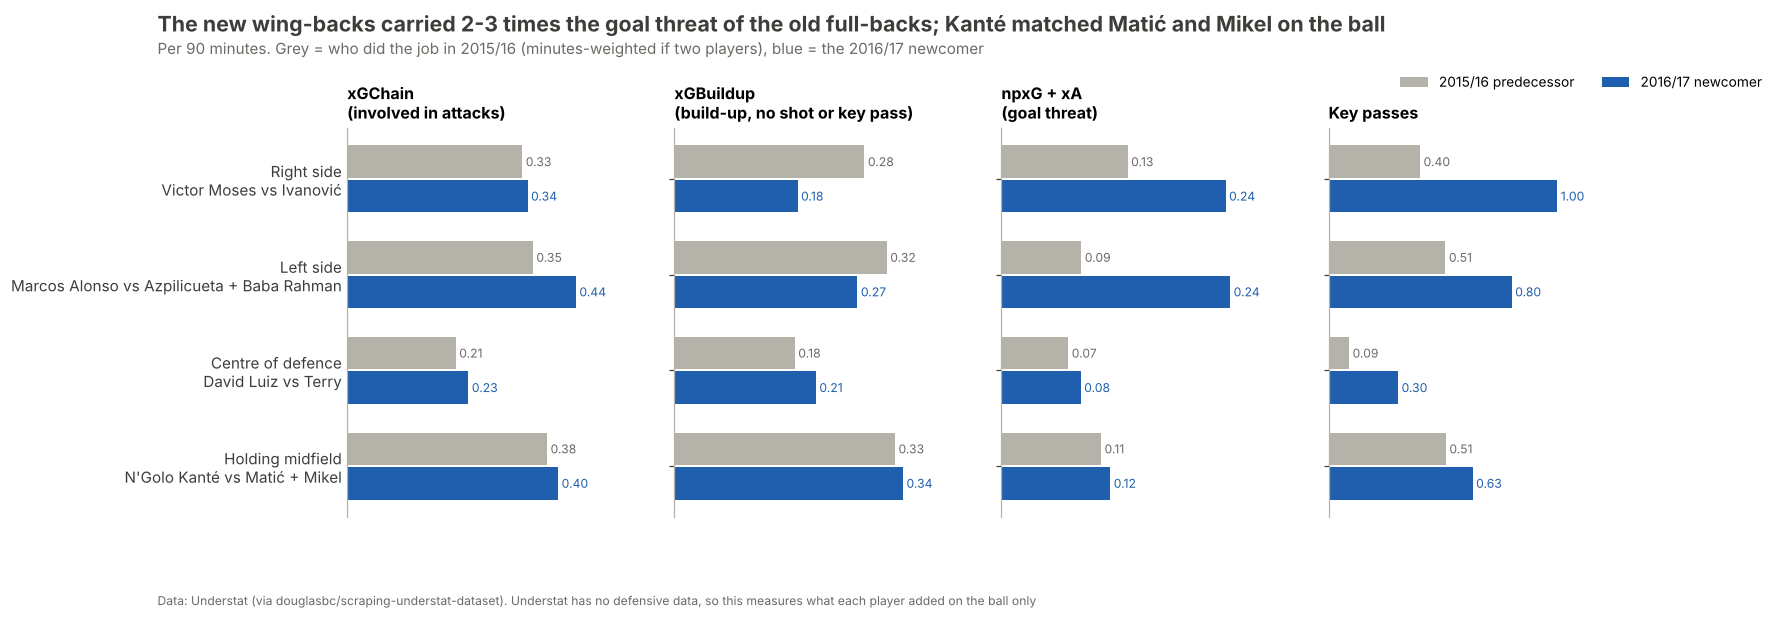

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.6), sharey=True)
y = np.arange(len(PR))[::-1]
for ax, (k, lab) in zip(axes, METRICS):
    o, c = PR[f"old_{k}"].values, PR[f"new_{k}"].values
    ax.barh(y + 0.18, o, height=0.34, color=GREY, label="2015/16 predecessor")
    ax.barh(y - 0.18, c, height=0.34, color=BLUE, label="2016/17 newcomer")
    for yi, oi, ci in zip(y, o, c):
        ax.text(oi, yi + 0.18, f" {oi:.2f}", va="center", fontsize=8, color=MUTED)
        ax.text(ci, yi - 0.18, f" {ci:.2f}", va="center", fontsize=8, color=BLUE)
    ax.set_title(lab, fontsize=10.5)
    ax.set_xlim(0, max(o.max(), c.max()) * 1.3)
    ax.grid(axis="y", visible=False)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
axes[0].set_yticks(y)
axes[0].set_yticklabels([f"{r.role}\n{r.new} vs {r.old}" for r in PR.itertuples()])
axes[0].tick_params(axis="y", length=0)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h[:2], l[:2], loc="lower right", bbox_to_anchor=(0.99, 0.93), fontsize=9, frameon=False, ncol=2)
fig.subplots_adjust(wspace=0.1)
titles(fig, "The new wing-backs carried 2-3 times the goal threat of the old full-backs; Kanté matched Matić and Mikel on the ball",
       "Per 90 minutes. Grey = who did the job in 2015/16 (minutes-weighted if two players), blue = the 2016/17 newcomer",
       SRC_U + ". Understat has no defensive data, so this measures what each player added on the ball only")
fig.savefig(FIGS / "19_newcomers_vs_predecessors.png")